# Lesson 14 — Model Calibration and Probability Reliability

## Project Overview

This project evaluates the reliability of predicted probabilities from machine learning classification models using a synthetic disease surveillance dataset.

The analysis investigates whether predicted confirmation probabilities agree with observed outcomes and whether additional calibration improves probability quality.

## Dataset and Methodology

- **Dataset:** 2,000 synthetic surveillance observations.
- **Predictors:** Age, Fever, Headache, Animal Exposure, Travel History, and Symptom Duration.
- **Outcome:** Simulated laboratory confirmation (binary).
- **Data split:** 80% training and 20% testing, using stratified sampling.
- **Base model:** Logistic Regression with standardized predictors.
- **Calibration methods:** Original probabilities, sigmoid calibration, and isotonic calibration.
- **Evaluation metrics:** Brier score, log loss, ROC-AUC, Expected Calibration Error (ECE), and Maximum Calibration Error (MCE).
- **Visualizations:** Reliability diagrams comparing predicted probabilities with observed confirmation frequencies.

## Key Findings

The original Logistic Regression model achieved:

| Metric | Result |
|---|---:|
| ROC-AUC | 0.7736 |
| Brier score | 0.1870 |
| Log loss | 0.5554 |
| Expected Calibration Error | 0.0436 |
| Maximum Calibration Error | 0.1123 |

Additional calibration did not improve probability quality on the held-out test set.

| Method | Brier Score | Log Loss |
|---|---:|---:|
| Original Logistic Regression | 0.1870 | 0.5554 |
| Sigmoid Calibration | 0.1873 | 0.5558 |
| Isotonic Calibration | 0.1889 | 0.5651 |

The original Logistic Regression model was therefore provisionally preferred for this exercise.

## Interpretation and Limitations

The model demonstrated useful discrimination and reasonably close agreement between predicted probabilities and observed outcomes across most probability groups.

However, calibration estimates are affected by sample size and binning choices. The test dataset was also used to compare calibration methods, so an independent validation dataset would be required to confirm the preferred approach without selection bias.

All observations and outcomes are synthetic. The results do not establish real epidemiological relationships and should not be used for clinical diagnosis or operational disease surveillance.

**This project is intended for educational demonstration of machine learning probability calibration.**

In [1]:
import sys

print("Python version:", sys.version.split()[0])
print("LESSON 14 — Kernel is working!")

Python version: 3.14.4
LESSON 14 — Kernel is working!


In [2]:
# LESSON 14 — STEP 9
# Create a synthetic disease surveillance dataset

import numpy as np
import pandas as pd

rng = np.random.default_rng(42)

n = 2000

df = pd.DataFrame({
    "Age": rng.integers(1, 85, n),
    "Fever": rng.binomial(1, 0.55, n),
    "Headache": rng.binomial(1, 0.40, n),
    "Animal_Exposure": rng.binomial(1, 0.20, n),
    "Travel_History": rng.binomial(1, 0.25, n),
    "Symptom_Duration": rng.integers(1, 15, n)
})

# Simulate probability of laboratory confirmation
log_odds = (
    -3.5
    + 0.025 * df["Age"]
    + 1.2 * df["Fever"]
    + 0.5 * df["Headache"]
    + 1.4 * df["Animal_Exposure"]
    + 0.6 * df["Travel_History"]
    + 0.08 * df["Symptom_Duration"]
)

probability = 1 / (1 + np.exp(-log_odds))

df["Confirmed"] = rng.binomial(1, probability)

print("LESSON 14 — SYNTHETIC SURVEILLANCE DATASET")
print("=" * 50)
print("Dataset shape:", df.shape)
print("\nConfirmation distribution:")
print(df["Confirmed"].value_counts())
print("\nConfirmation rate:")
print(f"{df['Confirmed'].mean():.2%}")

display(df.head())

LESSON 14 — SYNTHETIC SURVEILLANCE DATASET
Dataset shape: (2000, 7)

Confirmation distribution:
Confirmed
0    1219
1     781
Name: count, dtype: int64

Confirmation rate:
39.05%


,Age,Fever,Headache,Animal_Exposure,Travel_History,Symptom_Duration,Confirmed
0,8,1,1,0,0,11,1
1,66,1,0,0,1,13,1
2,55,1,0,0,0,3,0
3,37,1,1,0,0,4,0
4,37,0,0,0,1,1,0


In [3]:
# LESSON 14 — STEP 10
# Train Logistic Regression and generate probabilities

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

X = df.drop(columns="Confirmed")
y = df["Confirmed"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42)
)

model.fit(X_train, y_train)

# Probabilities for the positive class
y_prob = model.predict_proba(X_test)[:, 1]

print("LESSON 14 — MODEL TRAINING")
print("=" * 45)
print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))
print("Training confirmation rate:", f"{y_train.mean():.2%}")
print("Testing confirmation rate:", f"{y_test.mean():.2%}")
print("Minimum predicted probability:", f"{y_prob.min():.4f}")
print("Maximum predicted probability:", f"{y_prob.max():.4f}")
print("Mean predicted probability:", f"{y_prob.mean():.4f}")
print("Model training: SUCCESS")

LESSON 14 — MODEL TRAINING
Training observations: 1600
Testing observations: 400
Training confirmation rate: 39.06%
Testing confirmation rate: 39.00%
Minimum predicted probability: 0.0385
Maximum predicted probability: 0.9248
Mean predicted probability: 0.3870
Model training: SUCCESS


In [4]:
# LESSON 14 — STEP 11
# Evaluate predicted probability quality

from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score

brier = brier_score_loss(y_test, y_prob)
logloss = log_loss(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)

# Baseline: predict the training confirmation rate for everyone
baseline_prob = np.full(len(y_test), y_train.mean())
baseline_brier = brier_score_loss(y_test, baseline_prob)

print("LESSON 14 — PROBABILITY QUALITY ASSESSMENT")
print("=" * 50)
print(f"Model Brier score:    {brier:.4f}")
print(f"Baseline Brier score: {baseline_brier:.4f}")
print(f"Log loss:             {logloss:.4f}")
print(f"ROC-AUC:              {auc:.4f}")
print("=" * 50)

if brier < baseline_brier:
    print("RESULT: Model improves on the baseline Brier score.")
else:
    print("RESULT: Model does not improve on the baseline Brier score.")

LESSON 14 — PROBABILITY QUALITY ASSESSMENT
Model Brier score:    0.1870
Baseline Brier score: 0.2379
Log loss:             0.5554
ROC-AUC:              0.7736
RESULT: Model improves on the baseline Brier score.


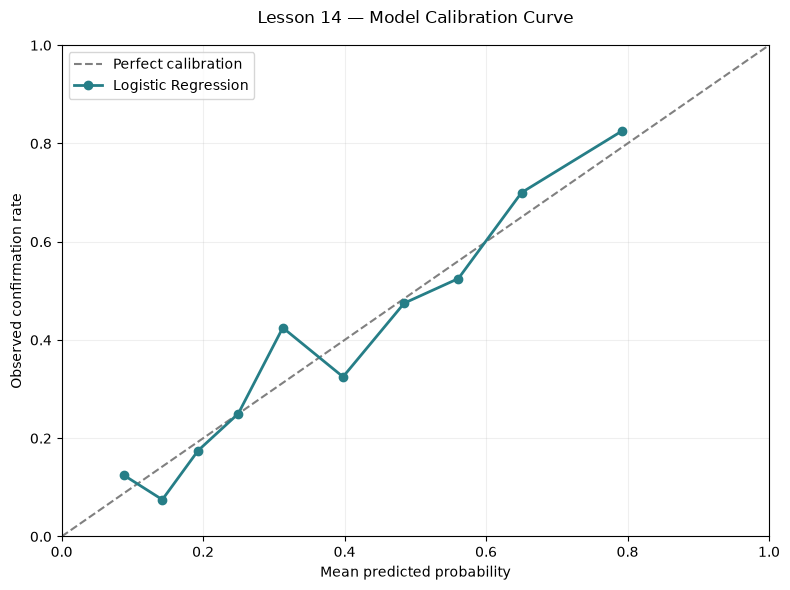

CALIBRATION RESULTS
Predicted: 0.088 | Observed: 0.125 | Difference: +0.037
Predicted: 0.142 | Observed: 0.075 | Difference: -0.067
Predicted: 0.193 | Observed: 0.175 | Difference: -0.018
Predicted: 0.250 | Observed: 0.250 | Difference: +0.000
Predicted: 0.313 | Observed: 0.425 | Difference: +0.112
Predicted: 0.398 | Observed: 0.325 | Difference: -0.073
Predicted: 0.484 | Observed: 0.475 | Difference: -0.009
Predicted: 0.561 | Observed: 0.525 | Difference: -0.036
Predicted: 0.650 | Observed: 0.700 | Difference: +0.050
Predicted: 0.792 | Observed: 0.825 | Difference: +0.033


In [5]:
# LESSON 14 — STEP 12
# Calibration curve / Reliability diagram

from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

fraction_positive, mean_predicted = calibration_curve(
    y_test,
    y_prob,
    n_bins=10,
    strategy="quantile"
)

plt.figure(figsize=(8, 6))

# Perfect calibration reference
plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Perfect calibration"
)

# Actual model calibration
plt.plot(
    mean_predicted,
    fraction_positive,
    marker="o",
    linewidth=2,
    color="#267E87",
    label="Logistic Regression"
)

plt.xlabel("Mean predicted probability")
plt.ylabel("Observed confirmation rate")
plt.title("Lesson 14 — Model Calibration Curve", pad=16)

plt.xlim(0, 1)
plt.ylim(0, 1)
plt.grid(alpha=0.2)
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

print("CALIBRATION RESULTS")
print("=" * 45)

for predicted, observed in zip(mean_predicted, fraction_positive):
    print(
        f"Predicted: {predicted:.3f} | "
        f"Observed: {observed:.3f} | "
        f"Difference: {observed - predicted:+.3f}"
    )

In [6]:
# LESSON 14 — STEP 13
# Expected Calibration Error (ECE)
# Maximum Calibration Error (MCE)

import numpy as np
import pandas as pd

# Create 10 groups containing approximately equal numbers
calibration_df = pd.DataFrame({
    "Actual": np.asarray(y_test),
    "Predicted": y_prob
})

calibration_df["Bin"] = pd.qcut(
    calibration_df["Predicted"],
    q=10,
    labels=False,
    duplicates="drop"
)

calibration_summary = (
    calibration_df
    .groupby("Bin")
    .agg(
        Count=("Actual", "size"),
        Mean_Predicted=("Predicted", "mean"),
        Observed_Rate=("Actual", "mean")
    )
    .reset_index()
)

calibration_summary["Absolute_Error"] = abs(
    calibration_summary["Observed_Rate"]
    - calibration_summary["Mean_Predicted"]
)

ece = (
    calibration_summary["Count"]
    * calibration_summary["Absolute_Error"]
).sum() / len(calibration_df)

mce = calibration_summary["Absolute_Error"].max()

print("LESSON 14 — CALIBRATION ERROR ASSESSMENT")
print("=" * 50)
print(f"Expected Calibration Error (ECE): {ece:.4f}")
print(f"Maximum Calibration Error (MCE):  {mce:.4f}")
print("=" * 50)

display(calibration_summary.round(4))

LESSON 14 — CALIBRATION ERROR ASSESSMENT
Expected Calibration Error (ECE): 0.0436
Maximum Calibration Error (MCE):  0.1123


,Bin,Count,Mean_Predicted,Observed_Rate,Absolute_Error
0,0,40,0.0877,0.125,0.0373
1,1,40,0.1424,0.075,0.0674
2,2,40,0.1930,0.175,0.0180
3,3,40,0.2497,0.250,0.0003
4,4,40,0.3127,0.425,0.1123
5,5,40,0.3978,0.325,0.0728
6,6,40,0.4843,0.475,0.0093
7,7,40,0.5608,0.525,0.0358
8,8,40,0.6502,0.700,0.0498
9,9,40,0.7917,0.825,0.0333


In [7]:
# LESSON 14 — STEP 14
# Compare original, sigmoid, and isotonic calibration

from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
import pandas as pd

def build_model():
    return make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000, random_state=42)
    )

# Calibrated models use cross-validation on training data
sigmoid_model = CalibratedClassifierCV(
    estimator=build_model(),
    method="sigmoid",
    cv=5
)

isotonic_model = CalibratedClassifierCV(
    estimator=build_model(),
    method="isotonic",
    cv=5
)

sigmoid_model.fit(X_train, y_train)
isotonic_model.fit(X_train, y_train)

# Evaluate all models on the same held-out test data
models = {
    "Original Logistic Regression": model,
    "Sigmoid Calibration": sigmoid_model,
    "Isotonic Calibration": isotonic_model
}

results = []

for name, fitted_model in models.items():
    probabilities = fitted_model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Brier_Score": brier_score_loss(y_test, probabilities),
        "Log_Loss": log_loss(y_test, probabilities),
        "ROC_AUC": roc_auc_score(y_test, probabilities),
        "Mean_Probability": probabilities.mean()
    })

calibration_comparison = pd.DataFrame(results)

print("LESSON 14 — CALIBRATION METHOD COMPARISON")
print("=" * 55)

display(calibration_comparison.round(4))

LESSON 14 — CALIBRATION METHOD COMPARISON


,Model,Brier_Score,Log_Loss,ROC_AUC,Mean_Probability
0,Original Logistic Regression,0.1870,0.5554,0.7736,0.3870
1,Sigmoid Calibration,0.1873,0.5558,0.7736,0.3865
2,Isotonic Calibration,0.1889,0.5651,0.7733,0.3853


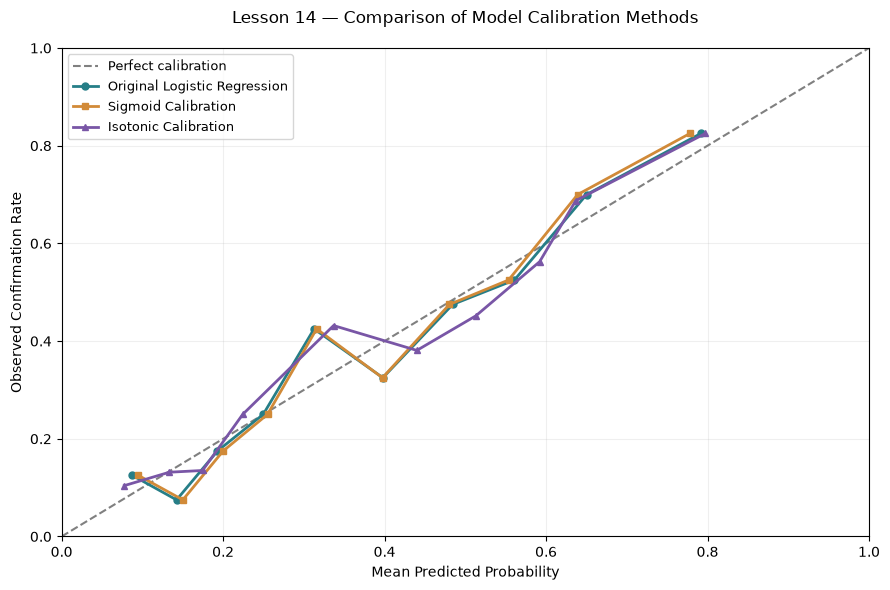

SUCCESS — Calibration comparison chart generated


In [8]:
# LESSON 14 — STEP 15
# Compare calibration curves for all three models

import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

plt.figure(figsize=(9, 6))

# Reference line
plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    linewidth=1.5,
    label="Perfect calibration"
)

styles = {
    "Original Logistic Regression": ("#267E87", "o"),
    "Sigmoid Calibration": ("#D18A38", "s"),
    "Isotonic Calibration": ("#7956A6", "^")
}

for name, fitted_model in models.items():

    probabilities = fitted_model.predict_proba(X_test)[:, 1]

    observed, predicted = calibration_curve(
        y_test,
        probabilities,
        n_bins=10,
        strategy="quantile"
    )

    color, marker = styles[name]

    plt.plot(
        predicted,
        observed,
        marker=marker,
        linewidth=2,
        markersize=5,
        color=color,
        label=name
    )

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Observed Confirmation Rate")
plt.title(
    "Lesson 14 — Comparison of Model Calibration Methods",
    pad=18
)

plt.xlim(0, 1)
plt.ylim(0, 1)
plt.grid(alpha=0.2)
plt.legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

print("SUCCESS — Calibration comparison chart generated")

In [9]:
# LESSON 14 — STEP 16
# Final technical audit

import numpy as np

checks = {
    "Dataset contains 2000 observations": len(df) == 2000,
    "Six predictors available": X_train.shape[1] == 6,
    "Training set contains 1600 observations": len(X_train) == 1600,
    "Test set contains 400 observations": len(X_test) == 400,
    "Predicted probabilities available": len(y_prob) == len(y_test),
    "Probabilities within valid range": np.all(
        (y_prob >= 0) & (y_prob <= 1)
    ),
    "Brier score calculated": 0 <= brier <= 1,
    "Calibration bins calculated": len(calibration_summary) == 10,
    "Calibration error calculated": np.isfinite(ece) and np.isfinite(mce),
    "Three calibration methods compared": len(calibration_comparison) == 3,
    "Original model has lowest Brier score": (
        calibration_comparison.loc[
            calibration_comparison["Brier_Score"].idxmin(), "Model"
        ] == "Original Logistic Regression"
    )
}

print("LESSON 14 — FINAL TECHNICAL AUDIT")
print("=" * 55)

for description, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'} | {description}")

print("=" * 55)

if all(checks.values()):
    print("Overall status: ALL CHECKS PASSED")
else:
    print("Overall status: REVIEW REQUIRED")

LESSON 14 — FINAL TECHNICAL AUDIT
PASS | Dataset contains 2000 observations
PASS | Six predictors available
PASS | Training set contains 1600 observations
PASS | Test set contains 400 observations
PASS | Predicted probabilities available
PASS | Probabilities within valid range
PASS | Brier score calculated
PASS | Calibration bins calculated
PASS | Calibration error calculated
PASS | Three calibration methods compared
PASS | Original model has lowest Brier score
Overall status: ALL CHECKS PASSED
